# 03.P · Solution

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/03-classification/project/solution.ipynb)

One good way to do it, not the only one. Compare your numbers; small differences from random splits are normal.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, precision_recall_curve, average_precision_score)

def score_table(models, X_test, y_test):
    """One row per model: accuracy, precision, recall, F1, ROC-AUC on the test set."""
    rows = []
    for name, m in models.items():
        p = m.predict(X_test)
        proba = m.predict_proba(X_test)[:, 1] if hasattr(m, "predict_proba") else p
        rows.append(dict(model=name, accuracy=accuracy_score(y_test, p), precision=precision_score(y_test, p, zero_division=0),
                         recall=recall_score(y_test, p), f1=f1_score(y_test, p), roc_auc=roc_auc_score(y_test, proba)))
    return pd.DataFrame(rows).set_index("model").round(3)

# Part A: Titanic

## A1–A2. Load, fill, encode, split

In [2]:
titanic = sns.load_dataset("titanic")
print(titanic.shape)
print(titanic.isna().sum()[lambda s: s > 0])
titanic.head()

(891, 15)
age            177
embarked         2
deck           688
embark_town      2
dtype: int64


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
t = titanic.copy()
t["age"] = t["age"].fillna(t["age"].median())
t["embarked"] = t["embarked"].fillna(t["embarked"].mode()[0])
t["sex"] = (t["sex"] == "female").astype(int)                      # 1 = female
t["embarked"] = t["embarked"].map({"S": 0, "C": 1, "Q": 2})
feats_t = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
Xt_train, Xt_test, yt_train, yt_test = train_test_split(t[feats_t], t["survived"], test_size=0.25, random_state=42, stratify=t["survived"])
print(f"survival rate {t['survived'].mean():.1%}; train {len(Xt_train)}, test {len(Xt_test)}")

survival rate 38.4%; train 668, test 223


## A3–A4. Baselines, models, comparison

In [4]:
class RuleModel:
    """A hand-written rule wrapped so score_table can treat it like a model."""
    def __init__(self, fn): self.fn = fn
    def fit(self, X, y): return self
    def predict(self, X): return np.asarray(self.fn(X)).astype(int)

models_t = {
    "nobody survives":     RuleModel(lambda X: np.zeros(len(X))),
    "all women survive":   RuleModel(lambda X: X["sex"] == 1),
    "KNN (k=15, scaled)":  make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "decision tree (d=4)": DecisionTreeClassifier(max_depth=4, random_state=0),
    "logistic (scaled)":   make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}
for m in models_t.values():
    m.fit(Xt_train, yt_train)
score_table(models_t, Xt_test, yt_test)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
nobody survives,0.614,0.000,0.000,0.000,0.500
all women survive,0.767,0.712,0.663,0.687,0.747
"KNN (k=15, scaled)",0.821,0.829,0.674,0.744,0.848
decision tree (d=4),0.776,0.833,0.523,0.643,0.810
logistic (scaled),0.771,0.711,0.686,0.698,0.840


"All women survive" is a strong baseline: sex alone gets most of the way. The models add a little on top, mainly by combining sex with class and age.

## A5. What did the model learn?

In [5]:
from sklearn.tree import export_text
print(export_text(models_t["decision tree (d=4)"], feature_names=feats_t, max_depth=2))
coef = pd.Series(models_t["logistic (scaled)"][-1].coef_[0], index=feats_t).sort_values()
print(coef.round(2))

|--- sex <= 0.50
|   |--- age <= 3.50
|   |   |--- sibsp <= 2.50
|   |   |   |--- class: 1
|   |   |--- sibsp >  2.50
|   |   |   |--- truncated branch of depth 2
|   |--- age >  3.50
|   |   |--- pclass <= 1.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- pclass >  1.50
|   |   |   |--- truncated branch of depth 2
|--- sex >  0.50
|   |--- pclass <= 2.50
|   |   |--- fare <= 28.86
|   |   |   |--- truncated branch of depth 2
|   |   |--- fare >  28.86
|   |   |   |--- truncated branch of depth 2
|   |--- pclass >  2.50
|   |   |--- fare <= 7.89
|   |   |   |--- truncated branch of depth 2
|   |   |--- fare >  7.89
|   |   |   |--- truncated branch of depth 2

pclass     -0.93
age        -0.52
sibsp      -0.25
parch      -0.03
fare        0.13
embarked    0.21
sex         1.26
dtype: float64


The tree's first split is on `sex`; within men, age (boys fared better); within women, class. The logistic coefficients agree: being female is by far the strongest positive, higher `pclass` number (3rd class) the strongest negative.

# Part B: ShopWave churn

## B1. Customer table and baseline

In [6]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd, numpy as np
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail
from sklearn.model_selection import train_test_split

xlsx = ensure_online_retail()
csv = xlsx.with_name("online_retail_2010_2011.csv")          # fast cache written by lesson 01.3
raw = pd.read_csv(csv, parse_dates=["InvoiceDate"]) if csv.exists() else pd.read_excel(xlsx, sheet_name="Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [7]:
majority = max(y_test.mean(), 1 - y_test.mean())
print(f"majority-class baseline accuracy on test: {majority:.3f}  (churn rate {y_test.mean():.3f})")

majority-class baseline accuracy on test: 0.564  (churn rate 0.436)


## B2–B3. Four candidates and the comparison table

In [8]:
models = {
    "rule: days_since_last > 90": RuleModel(lambda X: X["days_since_last"] > 90),
    "KNN (k=15, scaled)":         make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "decision tree (d=4)":        DecisionTreeClassifier(max_depth=4, random_state=0),
    "logistic (scaled)":          make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}
for m in models.values():
    m.fit(X_train, y_train)
table = score_table(models, X_test, y_test)
table

,accuracy,precision,recall,f1,roc_auc
model,,,,,
rule: days_since_last > 90,0.617,0.564,0.536,0.550,0.608
"KNN (k=15, scaled)",0.645,0.593,0.591,0.592,0.715
decision tree (d=4),0.651,0.573,0.779,0.660,0.713
logistic (scaled),0.675,0.620,0.655,0.637,0.741


In [9]:
best_name = table["roc_auc"].idxmax()
best = models[best_name]
proba = best.predict_proba(X_test)[:, 1]
print("best by AUC:", best_name)
print(confusion_matrix(y_test, best.predict(X_test)))

best by AUC: logistic (scaled)
[[323 145]
 [125 237]]


## B4. Curves

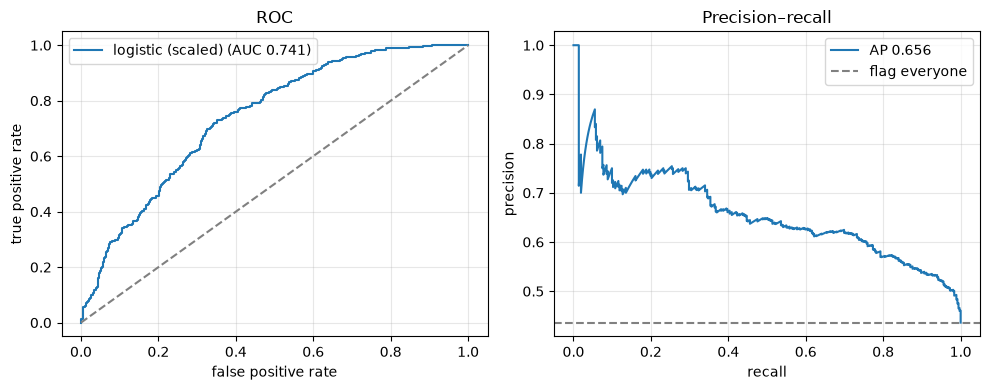

In [10]:
fpr, tpr, _ = roc_curve(y_test, proba)
prec, rec, _ = precision_recall_curve(y_test, proba)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(fpr, tpr, label=f"{best_name} (AUC {roc_auc_score(y_test, proba):.3f})"); ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(rec, prec, label=f"AP {average_precision_score(y_test, proba):.3f}"); ax[1].axhline(y_test.mean(), ls="--", color="gray", label="flag everyone")
ax[1].set(xlabel="recall", ylabel="precision", title="Precision–recall"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## B5. Threshold by cost

chosen threshold 0.14: cost £3,875  (flags 727 of 830 test customers)
default 0.5:        £9,410
voucher to everyone: £4,150
voucher to nobody:   £21,720


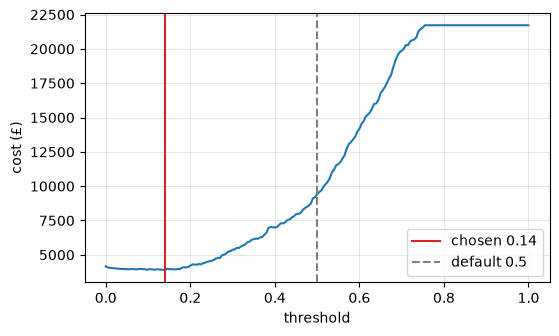

In [11]:
def cost(y, proba, t, c_voucher=5, c_lost=60):
    pred = (proba >= t).astype(int)
    flagged = pred.sum(); missed = ((y == 1) & (pred == 0)).sum()
    return c_voucher * flagged + c_lost * missed

ts = np.linspace(0, 1, 201)
costs = np.array([cost(y_test.values, proba, t) for t in ts])
best_t = ts[costs.argmin()]
print(f"chosen threshold {best_t:.2f}: cost £{costs.min():,}  (flags {(proba >= best_t).sum()} of {len(y_test)} test customers)")
print(f"default 0.5:        £{cost(y_test.values, proba, 0.5):,}")
print(f"voucher to everyone: £{cost(y_test.values, proba, 0.0):,}")
print(f"voucher to nobody:   £{cost(y_test.values, proba, 1.01):,}")
plt.figure(figsize=(6, 3.5)); plt.plot(ts, costs); plt.axvline(best_t, color="tab:red", label=f"chosen {best_t:.2f}")
plt.axvline(0.5, ls="--", color="gray", label="default 0.5"); plt.xlabel("threshold"); plt.ylabel("cost (£)"); plt.legend(); plt.grid(alpha=.3); plt.show()

In [12]:
summary = pd.DataFrame({
    "churn rate": [y_test.mean()],
    "best model": [best_name],
    "AUC": [roc_auc_score(y_test, proba)],
    "chosen threshold": [best_t],
    "recall at chosen t": [recall_score(y_test, (proba >= best_t).astype(int))],
    "precision at chosen t": [precision_score(y_test, (proba >= best_t).astype(int))],
    "vouchers per 100 customers": [100 * (proba >= best_t).mean()],
}).T.rename(columns={0: "value"})
summary

,value
churn rate,0.436145
best model,logistic (scaled)
AUC,0.740633
chosen threshold,0.14
recall at chosen t,0.98895
precision at chosen t,0.492435
vouchers per 100 customers,87.590361


## B6. Five insights for marketing

Write yours from *your* numbers; the shape should be like this (the figures below are illustrative and should be replaced by the ones printed above):

1. **Roughly four in ten customers who bought before September did not buy again by December.** Churn is the normal case, not a rare event, so "do nothing" is expensive.
2. **How recently a customer last ordered is the single strongest warning sign.** A simple rule, "no order in the last 90 days", already catches most churners; the model refines it with order count and spend.
3. **The model ranks customers well but not perfectly** (AUC in the printed table). Treat its output as a priority list, not a verdict.
4. **Send the voucher generously.** Because a lost customer costs twelve vouchers, the cheapest policy flags customers at a much lower probability than the default 50%. Expect to send vouchers to most of the list and to waste some; that is still far cheaper than missing churners.
5. **Measure it.** Hold back a random 10% of flagged customers from the voucher, and compare their return rate with the rest next quarter. That is the only way to know the £60 assumption and the voucher's effect are real. (Module 04 and 10 cover this properly.)